In [1]:
# EXP02 NumPy、SciPy、Matplotlib 与 pandas 数据处理
# 学号：20244080322  姓名：姚宇彬
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

STUDENT_ID = 20244080322
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

np.random.seed(42)


[Conda 环境] exp02
[学号] 20244080322
[机器指纹] 5752b9e6e61c9858
[RUN_ID] 20244080322-5752b9e6e61c9858


## 实验1 NumPy数组、数据类型与索引
1. 构建int/float/bool的ndarray，输出dtype、shape、ndim。
numpy数组全部元素必须同类型，内存连续，支持向量化运算；Python列表允许混合类型，存储对象指针。
2. np.arange(12) reshape为(3,4)、(2,3,2)；reshape条件：各维度乘积等于总元素数量。
3. (3,4)数组索引：取第2行；取1‑3列；布尔索引取大于6的元素。
4. 使用布尔条件`|`、`&`或者`np.logical_or`/`np.logical_and`筛选元素。
5. `*`/np.multiply是逐元素相乘；`@`/np.matmul是数学矩阵乘法。

In [2]:
# 实验1‑1 创建整数、浮点数、布尔ndarray，输出dtype、shape、ndim
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1, 2.2, 3.3])
arr_bool = np.array([True, False, True])

for name, arr in zip(["int数组","float数组","bool数组"], [arr_int, arr_float, arr_bool]):
    print(f"==== {name} ====")
    print(f"dtype: {arr.dtype}")
    print(f"shape: {arr.shape}")
    print(f"ndim: {arr.ndim}\n")


==== int数组 ====
dtype: int64
shape: (4,)
ndim: 1

==== float数组 ====
dtype: float64
shape: (3,)
ndim: 1

==== bool数组 ====
dtype: bool
shape: (3,)
ndim: 1



In [3]:
# 实验1‑2 reshape变形
a1 = np.arange(12)
a_34 = a1.reshape(3,4)
a_232 = a1.reshape(2,3,2)
print("np.arange(12):\n", a1)
print("\nreshape(3,4):\n", a_34)
print("\nreshape(2,3,2):\n", a_232)

# reshape条件：新shape各维度乘积必须等于数组总元素个数


np.arange(12):
 [ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [4]:
# 实验1‑3 数组索引切片
arr = np.arange(12).reshape(3,4)
print("原始数组：\n", arr)

row2 = arr[1, :]
col1_3 = arr[:, 0:3]
gt6 = arr[arr>6]

print("\n第2行：", row2, "shape:", row2.shape)
print("\n第1~3列：\n", col1_3, "shape:", col1_3.shape)
print("\n大于6的元素：", gt6, "shape:", gt6.shape)


原始数组：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第2行： [4 5 6 7] shape: (4,)

第1~3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)

大于6的元素： [ 7  8  9 10 11] shape: (5,)


In [5]:
# 实验1‑4 布尔索引
ar = np.arange(10)
cond1 = ar[(ar < 2) | (ar >7)]
cond2 = ar[(ar >3) & (ar <7)]
print("小于2或大于7：", cond1)
print("大于3且小于7：", cond2)

cond1_v2 = ar[np.logical_or(ar<2, ar>7)]
cond2_v2 = ar[np.logical_and(ar>3, ar<7)]
print("logical_or:", cond1_v2)
print("logical_and:", cond2_v2)


小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]
logical_or: [0 1 8 9]
logical_and: [4 5 6]


In [6]:
# 实验1‑5 逐元素乘法与矩阵乘法
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])
print("A:\n",A)
print("B:\n",B)
print("\nA * B 逐元素相乘：\n", A*B)
print("np.multiply(A,B)逐元素相乘：\n", np.multiply(A,B))
print("\nA @ B 矩阵乘法：\n", A @ B)
print("np.matmul(A,B)矩阵乘法：\n", np.matmul(A,B))


A:
 [[1 2]
 [3 4]]
B:
 [[5 6]
 [7 8]]

A * B 逐元素相乘：
 [[ 5 12]
 [21 32]]
np.multiply(A,B)逐元素相乘：
 [[ 5 12]
 [21 32]]

A @ B 矩阵乘法：
 [[19 22]
 [43 50]]
np.matmul(A,B)矩阵乘法：
 [[19 22]
 [43 50]]


## 实验2 随机抽样、统计与缺失值
1. np.random.normal生成成绩，np.clip限制0‑100，输出统计指标。
2. np.random.choice实现不放回均匀抽样与加权抽样。
3. permutation返回新数组，原数组不变；shuffle原地修改原数组。
4. np.nan会让普通统计函数输出nan；需要np.nanmean忽略缺失值。
5. 构造内存DataFrame，不写磁盘，供后续实验调用。


In [7]:
# 实验2‑1 生成模拟成绩，clip截断，统计指标
scores_raw = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores_raw, 0, 100)

n = len(scores)
min_s = np.min(scores)
max_s = np.max(scores)
mean_s = np.mean(scores)
std_s = np.std(scores)
ptp_s = np.ptp(scores)

print(f"样本数:{n}, min:{min_s:.2f}, max:{max_s:.2f}")
print(f"均值:{mean_s:.2f},标准差:{std_s:.2f},极差:{ptp_s:.2f}")


样本数:1000, min:37.59, max:100.00
均值:70.18,标准差:9.76,极差:62.41


In [8]:
# 实验2‑2 不放回抽样，均匀抽样、加权抽样
pop = np.arange(1,11)
sample_uniform = np.random.choice(pop, size=5, replace=False)

weights = pop / np.sum(pop)
sample_weighted = np.random.choice(pop, size=5, replace=False, p=weights)

print("均匀抽样：", sample_uniform)
print("加权抽样：", sample_weighted)


均匀抽样： [ 4  9  2  6 10]
加权抽样： [10  2  8  9  6]


In [21]:
# 实验2‑3 permutation(返回新数组) vs shuffle(原地修改)
ori_arr = np.array([1,2,3,4,5])
arr_shuffle_copy = np.random.permutation(ori_arr)
print("permutation前原数组：", ori_arr)
print("permutation返回新数组：", arr_shuffle_copy)
print("permutation后原数组：", ori_arr)

ori_arr2 = np.array([1,2,3,4,5])
print("shuffle前原数组：", ori_arr2)
np.random.shuffle(ori_arr2)
print("\nshuffle原地打乱之后原数组：", ori_arr2)


permutation前原数组： [1 2 3 4 5]
permutation返回新数组： [4 3 2 5 1]
permutation后原数组： [1 2 3 4 5]
shuffle前原数组： [1 2 3 4 5]

shuffle原地打乱之后原数组： [4 5 3 2 1]


In [10]:
# 实验2‑4 设置nan，对比普通均值与忽略nan均值
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan
cnt_nan = np.sum(np.isnan(scores_nan))
mean_normal = np.mean(scores_nan)
mean_nanignore = np.nanmean(scores_nan)

print(f"缺失值数量：{cnt_nan}")
print(f"普通np.mean(含nan): {mean_normal}")
print(f"np.nanmean忽略缺失均值: {mean_nanignore:.2f}")


缺失值数量：3
普通np.mean(含nan): nan
np.nanmean忽略缺失均值: 70.20


In [11]:
# 实验2‑5 构造内存表格，不写入磁盘
idx_arr = np.arange(len(scores_nan))
df_exp2 = pd.DataFrame({"index": idx_arr, "score": scores_nan})
print("实验2内存表格df_exp2前5行：")
print(df_exp2.head())


实验2内存表格df_exp2前5行：
   index      score
0      0  74.967142
1      1  68.617357
2      2  76.476885
3      3  85.230299
4      4  67.658466


## 实验3 SciPy数值计算与Matplotlib可视化
1. scipy.linalg.solve求解线性方程组，numpy代入验证。
2. scipy.optimize.root求解方程x²‑2=0正负根，设置不同初始猜测。
3. scipy.optimize.minimize求二次函数极小点，对比解析解。
4. scipy.stats.ttest_ind做独立样本t检验，p值和0.05比较判断显著性。
5. matplotlib绘制成绩直方图、箱线图；绘制y=x、y=x²、y=x³图像。


In [27]:
# 实验3 SciPy数值计算
from scipy import linalg, optimize, stats

# 1.解线性方程组 3x+y=9，x+2y=8
A_mat = np.array([[3, 1], [1, 2]])
b_vec = np.array([9, 8])
sol = linalg.solve(A_mat, b_vec)
print(f"方程组解 x={sol[0]}, y={sol[1]}")
verify = A_mat @ sol
print("代入验证 A@sol：", verify)

# 2.求 x^2‑2=0 的正负根
def f_root(x):
    return x**2 - 2
res_pos = optimize.root(f_root, x0=1.0)
res_neg = optimize.root(f_root, x0=-1.0)
print("\n正根求解结果：", res_pos.x, "成功：", res_pos.success, "函数值", f_root(res_pos.x))
print("负根求解结果：", res_neg.x, "成功：", res_neg.success, "函数值", f_root(res_neg.x))

# 3.求 f(x)=x²+x+2 极小值
def f_min(x):
    return x**2 + x + 2
res_min = optimize.minimize(f_min, x0=0)
print("\n极小点x：", res_min.x, "函数极小值：", res_min.fun)


# 4.独立样本t检验
s1 = np.random.normal(loc=0, scale=1, size=100)
s2 = np.random.normal(loc=1, scale=1, size=100)
t_stat, p_val = stats.ttest_ind(s1, s2)
print(f"\nt检验 t统计量={t_stat:.3f}, p值={p_val:.4f}")
alpha = 0.05
if p_val < alpha:
    print(f"p<{alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p≥{alpha}，不能拒绝原假设，无充分证据说明均值不同")


方程组解 x=2.0, y=3.0
代入验证 A@sol： [9. 8.]

正根求解结果： [1.41421356] 成功： True 函数值 [-8.8817842e-16]
负根求解结果： [-1.41421356] 成功： True 函数值 [-8.8817842e-16]

极小点x： [-0.50000001] 函数极小值： 1.75

t检验 t统计量=-6.641, p值=0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


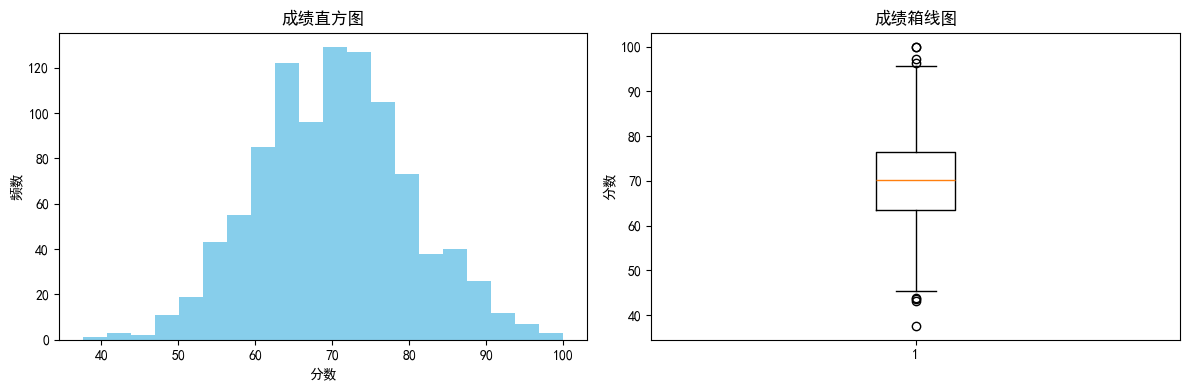

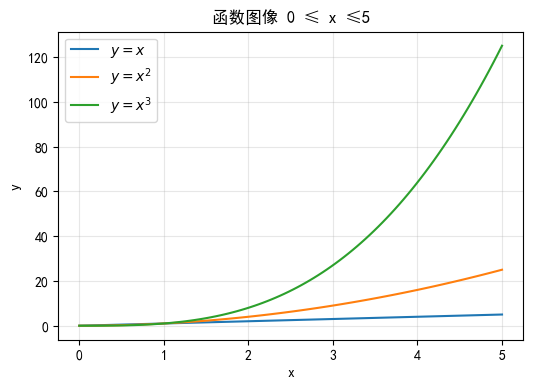

In [28]:
# 实验3‑5 matplotlib绘图：直方图、箱线图、函数曲线
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = ["SimHei"]  # 黑体，支持中文
plt.rcParams["axes.unicode_minus"] = False # 解决负号显示成方框
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(df_exp2["score"].dropna(), bins=20, color='skyblue')
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1,2,2)
plt.boxplot(df_exp2["score"].dropna())
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.tight_layout()
plt.show()

x_line = np.linspace(0, 5, 100)
y1 = x_line
y2 = x_line**2
y3 = x_line**3

plt.figure(figsize=(6,4))
plt.plot(x_line, y1, label="$y=x$")
plt.plot(x_line, y2, label="$y=x^2$")
plt.plot(x_line, y3, label="$y=x^3$")
plt.title("函数图像 0 ≤ x ≤5")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 实验4 pandas DataFrame
1. 根据字典构造DataFrame，设置Name为索引，新增Total总分、Average平均分。
2. loc基于标签索引，iloc基于位置索引；布尔筛选平均分>=80学生。
3. mean(axis=0)按列求均值；mean(axis=1)按行求均值。
4. apply按行求最高分；agg一次性输出多聚合统计；rank做成绩排名。
5. groupby分组统计；transform把分组聚合结果映射回每行。
6. filter筛选满足条件的分组。
7. cov协方差矩阵，corr皮尔逊相关矩阵；协方差反映变化方向，相关系数归一化衡量线性相关强弱。

协方差与相关系数说明：
- 协方差符号：正数说明两个科目成绩同向变化，负数代表反向变化。
- 协方差受数值量级影响；皮尔逊相关系数取值[-1,1]，越接近1代表强正相关，接近‑1强负相关，接近0无线性相关。


In [14]:
# 实验4‑1 创建DataFrame，新增Total、Average
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82]
}
df = pd.DataFrame(records)
df = df.set_index("Name")

df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n描述统计信息：")
print(df.describe())


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

描述统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [15]:
# 实验4‑2 loc iloc读取，筛选平均分>=80
print("=== loc读取Carol ===")
print(df.loc["Carol"])

print("\n=== iloc读取Carol ===")
print(df.iloc[1])

high_avg = df[df["Average"] >=80]
print("\n平均分≥80学生：")
print(high_avg)


=== loc读取Carol ===
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

=== iloc读取Carol ===
Group              A
Math              72
English           68
Python            80
Total            220
Average    73.333333
Name: Bob, dtype: object

平均分≥80学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [16]:
# 实验4‑3 axis=0列均值；axis=1行均值
col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("各科列均值(axis=0):")
print(col_mean)
print("\n每个学生行均值(axis=1):")
print(row_mean)


各科列均值(axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个学生行均值(axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [17]:
# 实验4‑4 apply、agg、rank
df["max_subject"] = df[["Math","English","Python"]].apply(max, axis=1)
print("每行科目最高分：")
print(df["max_subject"])

agg_res = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\nagg聚合min mean max：")
print(agg_res)

df["Math_rank"] = df["Math"].rank(ascending=False)
print("\nMath成绩排名：")
print(df[["Math","Math_rank"]])


每行科目最高分：
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: max_subject, dtype: int64

agg聚合min mean max：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Math成绩排名：
       Math  Math_rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


In [18]:
# 实验4‑5 groupby分组统计、transform
grouped = df.groupby("Group")
print("每组人数：")
print(grouped.size())
print("\n每组三科平均分：")
print(grouped[["Math","English","Python"]].mean())

df["Group_Python_mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加组Python平均分后的df：")
print(df)


每组人数：
Group
A    3
B    3
dtype: int64

每组三科平均分：
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

增加组Python平均分后的df：
      Group  Math  English  Python  Total    Average  max_subject  Math_rank  \
Name                                                                           
Alice     A    88       90      95    273  91.000000           95        2.0   
Bob       A    72       68      80    220  73.333333           80        5.0   
Carol     B    91       85      89    265  88.333333           91        1.0   
David     B    65       73      70    208  69.333333           73        6.0   
Eva       A    79       92      86    257  85.666667           92        4.0   
Frank     B    84       77      82    243  81.000000           84        3.0   

       Group_Python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  


In [19]:
# 实验4‑6 filter过滤分组
group_filtered = grouped.filter(lambda g: g["Python"].mean() >= 80)
print("filter过滤，Python组平均分>=80的组数据：")
print(group_filtered)


filter过滤，Python组平均分>=80的组数据：
      Group  Math  English  Python  Total    Average  max_subject  Math_rank  \
Name                                                                           
Alice     A    88       90      95    273  91.000000           95        2.0   
Bob       A    72       68      80    220  73.333333           80        5.0   
Carol     B    91       85      89    265  88.333333           91        1.0   
David     B    65       73      70    208  69.333333           73        6.0   
Eva       A    79       92      86    257  85.666667           92        4.0   
Frank     B    84       77      82    243  81.000000           84        3.0   

       Group_Python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [20]:
# 实验4‑7 协方差矩阵、相关系数矩阵
score_cols = ["Math","English","Python"]
cov_matrix = df[score_cols].cov()
corr_matrix = df[score_cols].corr()
print("协方差矩阵：")
print(cov_matrix)
print("\n皮尔逊相关系数矩阵：")
print(corr_matrix)


协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
